In [11]:
import numpy as np
import pandas as pd
from itertools import chain
import MDAnalysis as mda

# ================= 用户自定义 =================
contact_cutoff = 8.0
n_trajectories = 10
# =============================================

def find_continuous_segments(filename):
    df = pd.read_csv(filename, delim_whitespace=True, header=None)
    df['condition'] = (df.iloc[:, 1] > 0.8) & (df.iloc[:, 2] > 0.8)
    df['group'] = (df['condition'] != df['condition'].shift()).cumsum()
    filtered_df = df[df['condition']].groupby('group')[0].agg(['first', 'last'])
    ranges = [range(int(row['first']), int(row['last']) + 1) for _, row in filtered_df.iterrows()]
    return list(chain(*ranges))

# 初始化统计
contact_frame_counts = None
total_frames = 0

for i in range(1, n_trajectories + 1):
    print(f"\n🔄 正在处理轨迹 {i} ...")

    # 文件路径
    pdb_path = f"/hpc2hdd/home/jchen901/data/genesis/GENESIS_Tutorials-2022/Works/SMC_AICG2+/Full_removLig+98bp/021_delPartGo/021_nonspecific_DNAout_0.35/para_0.6/0.35-{i}/run1/pro_dna_test_run.pdb"
    dcd_path = f"/hpc2hdd/home/jchen901/data/genesis/GENESIS_Tutorials-2022/Works/SMC_AICG2+/Full_removLig+98bp/021_delPartGo/021_nonspecific_DNAout_0.35/para_0.6/0.35-{i}/run1/pro_dna_test_run.dcd"
    colvar_path = f"/hpc2hdd/home/jchen901/data/genesis/GENESIS_Tutorials-2022/Works/SMC_AICG2+/Full_removLig+98bp/021_delPartGo/analysis/para_nonspecific0.6/All_knetics/order_parameter/0.35/COLVAR{i}"

    selected_frames = set(find_continuous_segments(colvar_path))
    print(f"🔍 筛选出的有效帧数: {len(selected_frames)}")

    u = mda.Universe(pdb_path, dcd_path)
    protein = u.select_atoms("name CA and bynum 1:848")
    dna = u.select_atoms("(name DP or name DS or name DB) and bynum 991:1576")

    n_residues = len(protein)
    if contact_frame_counts is None:
        contact_frame_counts = np.zeros(n_residues, dtype=int)

    frame_counter = 0

    for ts in u.trajectory:
        if ts.frame not in selected_frames:
            continue
        frame_counter += 1

        dists = np.linalg.norm(
            protein.positions[:, np.newaxis, :] - dna.positions[np.newaxis, :, :],
            axis=2
        )
        # 判断是否有接触（按残基为单位）
        has_contact = (dists < contact_cutoff).any(axis=1).astype(int)
        contact_frame_counts += has_contact

    total_frames += frame_counter
    print(f"✅ 轨迹 {i} 的有效帧数: {frame_counter}")

# 平均接触频率 = 接触帧数 / 总帧数
contact_frequency = contact_frame_counts / total_frames

# 输出统计
print(f"\n📊 所有轨迹总有效帧数: {total_frames}")
print(f"📌 有接触的蛋白残基数: {(contact_frequency > 0).sum()}")
print(f"📈 接触频率总和: {contact_frequency.sum():.2f}")

# 保存结果
output_df = pd.DataFrame({
    "Protein_CA_Index": range(len(protein)),
    "Contact_Frequency": contact_frequency
})
output_df.to_csv("contact_frequency_per_residue.csv", index=False)
print("✅ 接触频率数据已保存为 contact_frequency_per_residue.csv")



🔄 正在处理轨迹 1 ...


/tmp/ipykernel_2575679/2364186654.py:12: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(filename, delim_whitespace=True, header=None)


🔍 筛选出的有效帧数: 30176


/hpc2hdd/home/jchen901/anaconda3/envs/CJY/lib/python3.10/site-packages/MDAnalysis/topology/PDBParser.py:350: UserWarning: Element information is missing, elements attribute will not be populated. If needed these can be guessed using universe.guess_TopologyAttrs(context='default', to_guess=['elements']).
  warnings.warn("Element information is missing, elements attribute "
/hpc2hdd/home/jchen901/anaconda3/envs/CJY/lib/python3.10/site-packages/MDAnalysis/coordinates/DCD.py:165: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


✅ 轨迹 1 的有效帧数: 30176

🔄 正在处理轨迹 2 ...


/tmp/ipykernel_2575679/2364186654.py:12: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(filename, delim_whitespace=True, header=None)


... (31 outputs left out)

/tmp/ipykernel_2575679/2364186654.py:12: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(filename, delim_whitespace=True, header=None)


🔍 筛选出的有效帧数: 38445


/hpc2hdd/home/jchen901/anaconda3/envs/CJY/lib/python3.10/site-packages/MDAnalysis/topology/PDBParser.py:350: UserWarning: Element information is missing, elements attribute will not be populated. If needed these can be guessed using universe.guess_TopologyAttrs(context='default', to_guess=['elements']).
  warnings.warn("Element information is missing, elements attribute "
/hpc2hdd/home/jchen901/anaconda3/envs/CJY/lib/python3.10/site-packages/MDAnalysis/coordinates/DCD.py:165: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


✅ 轨迹 10 的有效帧数: 38445

📊 所有轨迹总有效帧数: 316380
📌 有接触的蛋白残基数: 258
📈 接触频率总和: 9.87
✅ 接触频率数据已保存为 contact_frequency_per_residue.csv


# log scale可以显示出较低的但是有数值的区域

# 结合三个晶体结构的结果

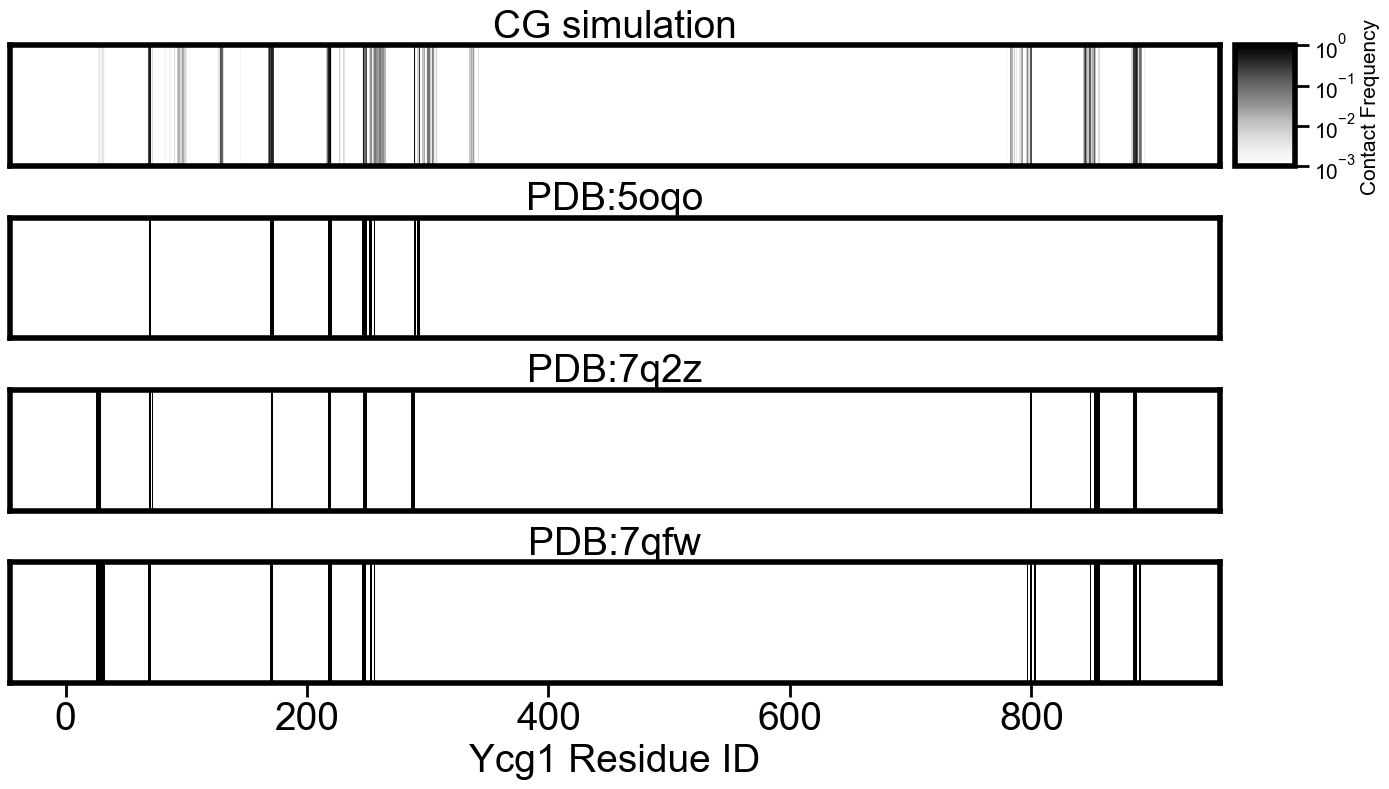

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import NullLocator

plt.rcParams.update({
    'font.family': 'Arial',  # 设置字体
    'axes.titlesize': 28,  # 标题字体大小
    'axes.labelsize': 28,  # 坐标轴标签字体大小
    'xtick.labelsize': 28,  # X轴刻度字体大小
    'ytick.labelsize': 28,  # Y轴刻度字体大小
    'legend.fontsize': 28,  # 图例字体大小
    'figure.figsize': (14, 8),  # 增加图像宽度，为color bar留出空间
    'axes.linewidth': 4,  # 坐标轴线宽
    'xtick.major.size': 10, # x 轴主刻度长度
    'ytick.major.size': 10, # y 轴主刻度长度
    'xtick.minor.size': 3, # x 轴次刻度长度
    'ytick.minor.size': 2, # y 轴主刻度长度
    'xtick.major.width': 2, # x 轴主刻度线宽
    'ytick.major.width': 2, # y 轴主刻度线宽
    'xtick.minor.width': 2, # x 轴次刻度线宽
    'ytick.minor.width': 2, # y 轴主刻度线宽
    'legend.fontsize': 24,    # 图例字体大小
    'axes.grid': False,  # 关闭背景网格
})

# === 第一个子图数据处理 ===
# 读取数据
df = pd.read_csv("contact_frequency_per_residue.csv")

# 条件性调整 index：index > 493 的加 63，否则加 6
df["index_adj"] = df["Protein_CA_Index"].apply(lambda x: x + 63 if x > 492 else x + 6)

# 构建 index → contact 字典
index_contact_map = dict(zip(df["index_adj"], df["Contact_Frequency"]))
max_index = df["index_adj"].max()

# 构建完整编号范围，包含所有空缺
all_resids = np.arange(0, max_index + 1)

# 构建 contact 值数组，缺失为 0
contact_values1 = np.array([index_contact_map.get(i, 0) for i in all_resids])
x_coords1 = np.arange(len(all_resids))

# === 第二、三、四个子图数据处理 ===
# 加载黑白图数据
contact_values2 = np.loadtxt("/hpc2hdd/home/jchen901/data/genesis/GENESIS_Tutorials-2022/Works/SMC_AICG2+/Full_removLig+98bp/021_delPartGo/analysis/all_combine/DNA_curvature/PDB_angle/contact_5oqo.csv", delimiter=",")
contact_values3 = np.loadtxt("/hpc2hdd/home/jchen901/data/genesis/GENESIS_Tutorials-2022/Works/SMC_AICG2+/Full_removLig+98bp/021_delPartGo/analysis/all_combine/DNA_curvature/PDB_angle/contact_7q2z.csv", delimiter=",")
contact_values4 = np.loadtxt("/hpc2hdd/home/jchen901/data/genesis/GENESIS_Tutorials-2022/Works/SMC_AICG2+/Full_removLig+98bp/021_delPartGo/analysis/all_combine/DNA_curvature/PDB_angle/contact_7qfw.csv", delimiter=",")

x_coords_common = np.arange(len(contact_values2))  # 所有横坐标一致

# === 绘图 ===
fig = plt.figure(figsize=(14, 8))
gs = GridSpec(4, 2, width_ratios=[20, 1], height_ratios=[1, 1, 1, 1], figure=fig)

# --- 第一个子图: 灰度图 ---
ax1 = fig.add_subplot(gs[0, 0])
norm = LogNorm(vmin=1e-3, vmax=1)
cmap = plt.cm.Greys
colors1 = ['white' if v == 0 else cmap(norm(v)) for v in contact_values1]
ax1.bar(x_coords1, [1.0] * len(contact_values1), width=1.0, color=colors1, edgecolor='none')
ax1.set_ylim(0, 1)
ax1.set_yticks([])
ax1.set_xticks([])
ax1.set_title("CG simulation")

ax_cb = fig.add_subplot(gs[0, 1])
sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array(contact_values1[contact_values1 > 0])
cbar = fig.colorbar(sm, cax=ax_cb)
cbar.set_label("Contact Frequency",fontsize=15)
cbar.ax.yaxis.set_minor_locator(NullLocator())
cbar.ax.tick_params(labelsize=15)

# --- 第二个子图: 黑白图1: P ---
ax2 = fig.add_subplot(gs[1, 0])
colors2 = ['black' if v == 1 else 'white' for v in contact_values2]
ax2.bar(x_coords_common, [1.0] * len(contact_values2), width=1.0, color=colors2, edgecolor='none')
ax2.set_ylim(0, 1)
ax2.set_yticks([])
ax2.set_xticks([])
ax2.set_title("PDB:5oqo")
fig.add_subplot(gs[1, 1]).axis("off")

# --- 第三个子图: 黑白图2: P+S ---
ax3 = fig.add_subplot(gs[2, 0])
colors3 = ['black' if v == 1 else 'white' for v in contact_values3]
ax3.bar(x_coords_common, [1.0] * len(contact_values3), width=1.0, color=colors3, edgecolor='none')
ax3.set_ylim(0, 1)
ax3.set_yticks([])
ax3.set_xticks([])
ax3.set_title("PDB:7q2z")
fig.add_subplot(gs[2, 1]).axis("off")

# --- 第四个子图: 黑白图3: P+S+B ---
ax4 = fig.add_subplot(gs[3, 0])
colors4 = ['black' if v == 1 else 'white' for v in contact_values4]
ax4.bar(x_coords_common, [1.0] * len(contact_values4), width=1.0, color=colors4, edgecolor='none')
ax4.set_ylim(0, 1)
ax4.set_yticks([])
ax4.set_xlabel("Ycg1 Residue ID")
ax4.set_title("PDB:7qfw")
fig.add_subplot(gs[3, 1]).axis("off")

plt.tight_layout()
plt.show()